# Detailed Laboratory Session: PCA and LDA

**Course:** Machine Learning Laboratory
**Topic:** Principal Component Analysis and Linear Discriminant Analysis  
**Suggested duration:** 3 hours  
**Teaching dataset:** Wine dataset  
**Assignment dataset:** Digits dataset  
**Assignment marks:** 20

This notebook develops Principal Component Analysis (PCA) and Linear Discriminant Analysis (LDA) mathematically and computationally. Both methods are implemented from scratch using NumPy and verified using Scikit-learn.

## Learning objectives

After completing this session, a student should be able to:

1. explain the need for dimensionality reduction;
2. distinguish feature selection from feature extraction;
3. derive PCA using covariance matrices and eigendecomposition;
4. calculate explained variance and reconstruction error;
5. derive LDA using within-class and between-class scatter matrices;
6. state why LDA permits at most $C-1$ components;
7. implement PCA and LDA from scratch;
8. avoid preprocessing and dimensionality-reduction leakage;
9. compare unsupervised and supervised projections; and
10. evaluate the effect of dimensionality reduction on classification performance and training time.

## 1. Why dimensionality reduction?

High-dimensional data may contain redundant, correlated, noisy, or visually inaccessible features. Dimensionality reduction creates a smaller representation while preserving information relevant to a chosen objective.

Typical benefits include:

- faster model training and inference;
- reduced storage and memory requirements;
- removal of correlated or noisy directions;
- easier two- or three-dimensional visualization;
- improved numerical conditioning; and
- possible reduction of overfitting.

However, dimensionality reduction may discard useful information and can make transformed features less interpretable.

### Feature selection versus feature extraction

| Approach | Main idea | Example |
|---|---|---|
| Feature selection | Retain a subset of original variables | Select 5 of 20 measured features |
| Feature extraction | Construct new variables from combinations of originals | PCA and LDA components |

## 2. PCA versus LDA

| Property | PCA | LDA |
|---|---|---|
| Full name | Principal Component Analysis | Linear Discriminant Analysis |
| Learning type | Unsupervised | Supervised |
| Uses class labels? | No | Yes |
| Main objective | Maximize projected variance | Maximize class separation |
| Key matrices | Covariance matrix | Within- and between-class scatter matrices |
| Maximum components | At most number of input features | At most $\min(d,C-1)$ |
| Common applications | Compression, denoising, visualization | Supervised projection and classification |
| Sensitive to scaling? | Yes | Yes |

PCA can preserve a high-variance direction that is not useful for classification. LDA explicitly searches for directions that separate known classes, but it requires labels and makes assumptions about class structure.

## 3. Import the required libraries

In [ ]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=UserWarning)
np.set_printoptions(precision=4, suppress=True)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load and inspect the Wine dataset

The Wine dataset has 178 observations, 13 continuous chemical measurements, and 3 wine classes. It is small enough for transparent matrix calculations and contains enough dimensions to demonstrate meaningful reduction.

In [ ]:
wine = load_wine()
X_wine = wine.data.astype(float)
y_wine = wine.target.astype(int)

wine_frame = pd.DataFrame(X_wine, columns=wine.feature_names)
wine_frame["class"] = y_wine

print("Feature matrix shape:", X_wine.shape)
print("Target shape        :", y_wine.shape)
print("Class names         :", wine.target_names)
print("Class counts        :", np.bincount(y_wine))
wine_frame.head()

Feature matrix shape: (178, 13)
Target shape        : (178,)
Class names         : ['class_0' 'class_1' 'class_2']
Class counts        : [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


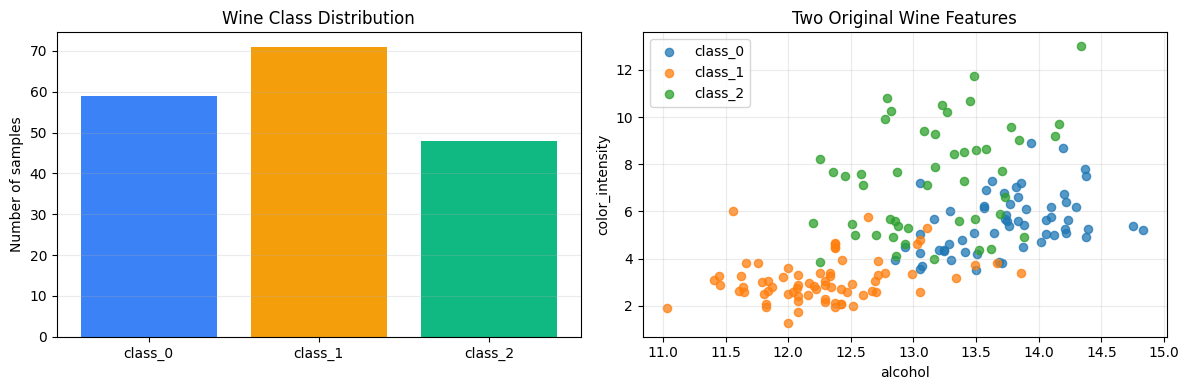

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    wine.target_names,
    np.bincount(y_wine),
    color=["#3b82f6", "#f59e0b", "#10b981"],
)
axes[0].set_title("Wine Class Distribution")
axes[0].set_ylabel("Number of samples")
axes[0].grid(axis="y", alpha=0.25)

for class_id, class_name in enumerate(wine.target_names):
    mask = y_wine == class_id
    axes[1].scatter(
        X_wine[mask, 0],
        X_wine[mask, 9],
        label=class_name,
        alpha=0.75,
        s=35,
    )
axes[1].set_xlabel(wine.feature_names[0])
axes[1].set_ylabel(wine.feature_names[9])
axes[1].set_title("Two Original Wine Features")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Leakage-free data splitting and scaling

PCA and LDA learn projection directions from data. Therefore, the scaler and dimensionality-reduction model must be fitted on the training set only. Fitting them before splitting would allow information from validation and test samples to influence the representation.

We create a stratified 70/15/15 split. Validation data is available for model decisions, while test data remains untouched until final evaluation.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_wine,
    y_wine,
    test_size=0.30,
    stratify=y_wine,
    random_state=RANDOM_STATE,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

split_table = pd.DataFrame({
    "subset": ["Training", "Validation", "Test"],
    "samples": [len(X_train_s), len(X_val_s), len(X_test_s)],
    "features": [X_train_s.shape[1], X_val_s.shape[1], X_test_s.shape[1]],
})
print(split_table.to_string(index=False))
print("Largest absolute training-feature mean:", np.abs(X_train_s.mean(axis=0)).max())
print("Mean training-feature standard deviation:", X_train_s.std(axis=0).mean())

    subset  samples  features
  Training      124        13
Validation       27        13
      Test       27        13
Largest absolute training-feature mean: 3.089822304823722e-15
Mean training-feature standard deviation: 1.0


# Part A: Principal Component Analysis

## 6. PCA intuition

PCA rotates the coordinate system so that:

- the first principal component captures the greatest possible variance;
- the second captures the greatest remaining variance while remaining orthogonal to the first; and
- later components continue under the same orthogonality constraint.

PCA does not use target labels. A high-variance direction is considered important even if it does not separate classes.

## 7. PCA mathematical derivation

For $m$ samples and $d$ features, center the data:

$$
\mathbf{X}_c=\mathbf{X}-\boldsymbol{\mu}.
$$

Calculate the sample covariance matrix:

$$
\mathbf{C}=\frac{1}{m-1}\mathbf{X}_c^T\mathbf{X}_c.
$$

Solve the eigenvalue problem:

$$
\mathbf{C}\mathbf{v}_j=\lambda_j\mathbf{v}_j.
$$

Sort eigenvalues from largest to smallest. The first $k$ eigenvectors form the projection matrix:

$$
\mathbf{W}_{PCA}=[\mathbf{v}_1,\ldots,\mathbf{v}_k].
$$

Transform the data:

$$
\mathbf{Z}=\mathbf{X}_c\mathbf{W}_{PCA}.
$$

The explained-variance ratio of component $j$ is:

$$
r_j=\frac{\lambda_j}{\sum_{i=1}^{d}\lambda_i}.
$$

## 8. PCA from scratch

`np.linalg.eigh` is used because the covariance matrix is real and symmetric. It returns real eigenvalues and orthonormal eigenvectors and is more appropriate here than the general `eig` routine.

In [ ]:
def fit_pca_scratch(X, n_components):
    if not 1 <= n_components <= X.shape[1]:
        raise ValueError("n_components must be between 1 and the number of features")

    mean = X.mean(axis=0, keepdims=True)
    X_centered = X - mean
    covariance = np.cov(X_centered, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    explained_variance_ratio = eigenvalues / eigenvalues.sum()
    components = eigenvectors[:, :n_components]

    return {
        "mean": mean,
        "covariance": covariance,
        "eigenvalues": eigenvalues,
        "explained_variance_ratio": explained_variance_ratio,
        "components": components,
    }


def transform_pca_scratch(X, model):
    return (X - model["mean"]) @ model["components"]


def inverse_transform_pca_scratch(Z, model):
    return Z @ model["components"].T + model["mean"]

In [ ]:
pca_scratch = fit_pca_scratch(X_train_s, n_components=2)
X_train_pca = transform_pca_scratch(X_train_s, pca_scratch)
X_val_pca = transform_pca_scratch(X_val_s, pca_scratch)
X_test_pca = transform_pca_scratch(X_test_s, pca_scratch)

print("Covariance shape      :", pca_scratch["covariance"].shape)
print("Component-matrix shape:", pca_scratch["components"].shape)
print("Training projection   :", X_train_pca.shape)
print("First five eigenvalues:", pca_scratch["eigenvalues"][:5])
print("Variance retained by 2 PCs:", pca_scratch["explained_variance_ratio"][:2].sum())

Covariance shape      : (13, 13)
Component-matrix shape: (13, 2)
Training projection   : (124, 2)
First five eigenvalues: [4.6827 2.5175 1.4425 0.9503 0.9139]
Variance retained by 2 PCs: 0.5493961699615938


## 9. Scree plot and cumulative explained variance

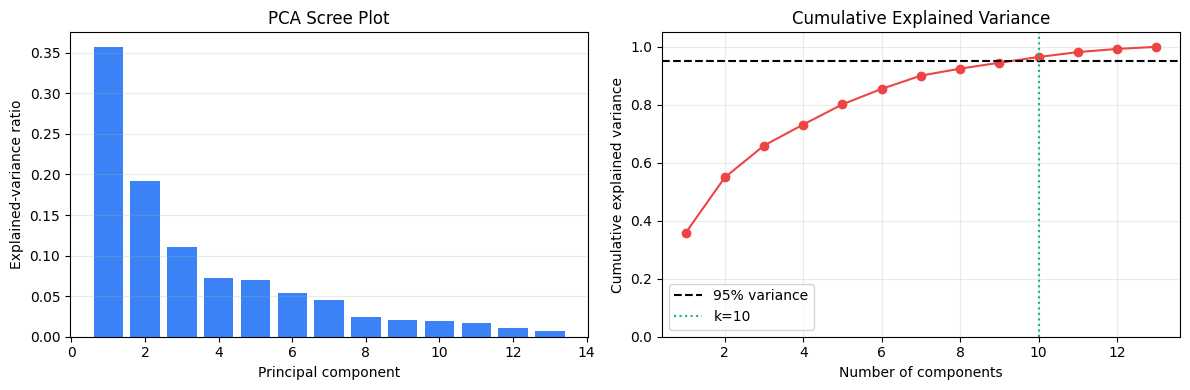

Components required for at least 95% variance: 10


In [ ]:
variance_ratio = pca_scratch["explained_variance_ratio"]
cumulative_variance = np.cumsum(variance_ratio)
components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(np.arange(1, len(variance_ratio) + 1), variance_ratio, color="#3b82f6")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained-variance ratio")
axes[0].set_title("PCA Scree Plot")
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="#ef4444",
)
axes[1].axhline(0.95, color="black", linestyle="--", label="95% variance")
axes[1].axvline(components_95, color="#10b981", linestyle=":", label=f"k={components_95}")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Cumulative Explained Variance")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f"Components required for at least 95% variance: {components_95}")

## 10. PCA reconstruction error

PCA permits an approximate reconstruction:

$$
\hat{\mathbf{X}}=\mathbf{Z}\mathbf{W}_{PCA}^T+\boldsymbol{\mu}.
$$

As more components are retained, reconstruction error cannot increase. Reconstruction quality is meaningful for PCA because its objective is related to variance preservation. LDA does not optimize reconstruction.

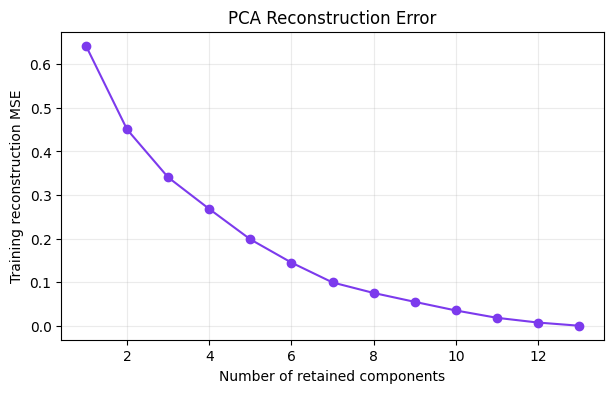

In [ ]:
reconstruction_rows = []

for k in range(1, X_train_s.shape[1] + 1):
    model_k = fit_pca_scratch(X_train_s, n_components=k)
    train_reduced = transform_pca_scratch(X_train_s, model_k)
    train_reconstructed = inverse_transform_pca_scratch(train_reduced, model_k)
    reconstruction_mse = np.mean((X_train_s - train_reconstructed) ** 2)
    reconstruction_rows.append({"components": k, "reconstruction_mse": reconstruction_mse})

reconstruction_table = pd.DataFrame(reconstruction_rows)

plt.figure(figsize=(7, 4))
plt.plot(
    reconstruction_table["components"],
    reconstruction_table["reconstruction_mse"],
    marker="o",
    color="#7c3aed",
)
plt.xlabel("Number of retained components")
plt.ylabel("Training reconstruction MSE")
plt.title("PCA Reconstruction Error")
plt.grid(alpha=0.25)
plt.show()

## 11. Two-dimensional PCA visualization

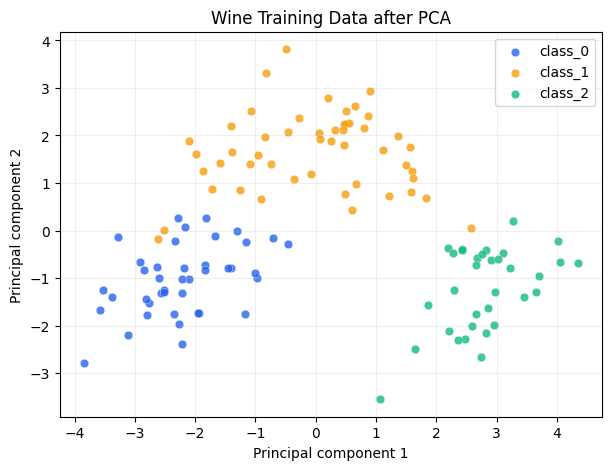

In [ ]:
def plot_projection(Z, labels, class_names, title, xlabel, ylabel):
    plt.figure(figsize=(7, 5))
    colors = ["#2563eb", "#f59e0b", "#10b981", "#ef4444", "#8b5cf6"]
    for class_id, class_name in enumerate(class_names):
        mask = labels == class_id
        plt.scatter(
            Z[mask, 0],
            Z[mask, 1],
            label=class_name,
            alpha=0.8,
            s=38,
            color=colors[class_id % len(colors)],
            edgecolor="white",
            linewidth=0.3,
        )
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


plot_projection(
    X_train_pca,
    y_train,
    wine.target_names,
    "Wine Training Data after PCA",
    "Principal component 1",
    "Principal component 2",
)

## 12. Verify PCA using Scikit-learn

Eigenvectors are direction vectors. Multiplying an eigenvector by $-1$ produces an equivalent direction, so component signs may differ between implementations without indicating an error.

In [ ]:
pca_sklearn = PCA(n_components=2)
X_train_pca_sklearn = pca_sklearn.fit_transform(X_train_s)
X_test_pca_sklearn = pca_sklearn.transform(X_test_s)

pca_verification = pd.DataFrame({
    "component": [1, 2],
    "scratch_variance_ratio": pca_scratch["explained_variance_ratio"][:2],
    "sklearn_variance_ratio": pca_sklearn.explained_variance_ratio_,
    "absolute_difference": np.abs(
        pca_scratch["explained_variance_ratio"][:2]
        - pca_sklearn.explained_variance_ratio_
    ),
})

print(pca_verification.to_string(index=False))
print("Maximum explained-variance difference:", pca_verification["absolute_difference"].max())

 component  scratch_variance_ratio  sklearn_variance_ratio  absolute_difference
         1                0.357305                0.357305         3.885781e-16
         2                0.192092                0.192092         5.551115e-17
Maximum explained-variance difference: 3.885780586188048e-16


# Part B: Linear Discriminant Analysis

## 13. LDA intuition

LDA uses labels and searches for a projection that simultaneously:

- keeps samples from the same class close together; and
- places different class means far apart.

This is expressed using two scatter matrices:

- **within-class scatter** $\mathbf{S}_W$ measures variation inside each class;
- **between-class scatter** $\mathbf{S}_B$ measures separation of class means.

## 14. LDA mathematical derivation

For class $c$, let $\boldsymbol{\mu}_c$ be its mean, $n_c$ its sample count, and $\boldsymbol{\mu}$ the global mean.

Within-class scatter:

$$
\mathbf{S}_W=\sum_{c=1}^{C}\sum_{\mathbf{x}_i\in c}
(\mathbf{x}_i-\boldsymbol{\mu}_c)(\mathbf{x}_i-\boldsymbol{\mu}_c)^T.
$$

Between-class scatter:

$$
\mathbf{S}_B=\sum_{c=1}^{C} n_c
(\boldsymbol{\mu}_c-\boldsymbol{\mu})(\boldsymbol{\mu}_c-\boldsymbol{\mu})^T.
$$

LDA maximizes the Fisher criterion:

$$
J(\mathbf{W})=\frac{|\mathbf{W}^T\mathbf{S}_B\mathbf{W}|}
{|\mathbf{W}^T\mathbf{S}_W\mathbf{W}|}.
$$

The projection directions are obtained from the generalized eigenvalue problem:

$$
\mathbf{S}_B\mathbf{w}=\lambda\mathbf{S}_W\mathbf{w}.
$$

In computation, we solve an equivalent eigenproblem involving $\mathbf{S}_W^{+}\mathbf{S}_B$, where $+$ denotes the pseudoinverse.

## 15. Why LDA has at most $C-1$ components

The centered class-mean vectors are linearly dependent because their weighted sum is zero. Therefore, the rank of $\mathbf{S}_B$ is at most $C-1$.

For the three Wine classes:

$$
k_{LDA}\le \min(d,C-1)=\min(13,2)=2.
$$

This limit depends on the number of classes, not only on the number of input features.

## 16. LDA from scratch

In [ ]:
def fit_lda_scratch(X, y, n_components=None, regularization=1e-6):
    classes = np.unique(y)
    n_features = X.shape[1]
    maximum_components = min(n_features, len(classes) - 1)

    if n_components is None:
        n_components = maximum_components
    if not 1 <= n_components <= maximum_components:
        raise ValueError(f"n_components must be between 1 and {maximum_components}")

    overall_mean = X.mean(axis=0, keepdims=True)
    within_scatter = np.zeros((n_features, n_features))
    between_scatter = np.zeros((n_features, n_features))
    class_means = {}

    for class_id in classes:
        X_class = X[y == class_id]
        class_mean = X_class.mean(axis=0, keepdims=True)
        class_means[int(class_id)] = class_mean

        centered_class = X_class - class_mean
        within_scatter += centered_class.T @ centered_class

        mean_difference = class_mean - overall_mean
        between_scatter += len(X_class) * (mean_difference.T @ mean_difference)

    scale = np.trace(within_scatter) / n_features
    within_regularized = within_scatter + regularization * scale * np.eye(n_features)
    discriminant_matrix = np.linalg.pinv(within_regularized) @ between_scatter

    eigenvalues, eigenvectors = np.linalg.eig(discriminant_matrix)
    eigenvalues = np.real_if_close(eigenvalues).real
    eigenvectors = np.real_if_close(eigenvectors).real

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    components = eigenvectors[:, :n_components]
    components /= np.linalg.norm(components, axis=0, keepdims=True)

    positive_eigenvalues = np.clip(eigenvalues, 0, None)
    discriminant_ratio = positive_eigenvalues / positive_eigenvalues.sum()

    return {
        "classes": classes,
        "overall_mean": overall_mean,
        "class_means": class_means,
        "within_scatter": within_scatter,
        "between_scatter": between_scatter,
        "eigenvalues": eigenvalues,
        "discriminant_ratio": discriminant_ratio,
        "components": components,
    }


def transform_lda_scratch(X, model):
    return (X - model["overall_mean"]) @ model["components"]

In [ ]:
lda_scratch = fit_lda_scratch(
    X_train_s,
    y_train,
    n_components=2,
    regularization=1e-6,
)

X_train_lda = transform_lda_scratch(X_train_s, lda_scratch)
X_val_lda = transform_lda_scratch(X_val_s, lda_scratch)
X_test_lda = transform_lda_scratch(X_test_s, lda_scratch)

print("Within-class scatter shape :", lda_scratch["within_scatter"].shape)
print("Between-class scatter shape:", lda_scratch["between_scatter"].shape)
print("LDA component shape        :", lda_scratch["components"].shape)
print("Training projection        :", X_train_lda.shape)
print("Leading eigenvalues        :", lda_scratch["eigenvalues"][:4])
print("Discriminant ratios        :", lda_scratch["discriminant_ratio"][:2])

Within-class scatter shape : (13, 13)
Between-class scatter shape: (13, 13)
LDA component shape        : (13, 2)
Training projection        : (124, 2)
Leading eigenvalues        : [9.9325 4.9604 0.     0.    ]
Discriminant ratios        : [0.6669 0.3331]


## 17. Two-dimensional LDA visualization

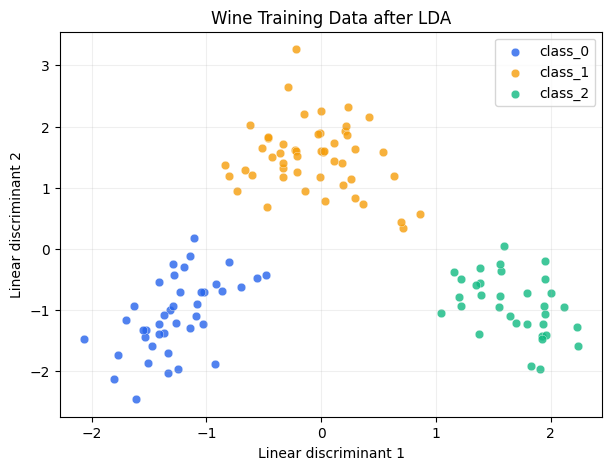

In [ ]:
plot_projection(
    X_train_lda,
    y_train,
    wine.target_names,
    "Wine Training Data after LDA",
    "Linear discriminant 1",
    "Linear discriminant 2",
)

## 18. Compare class separation numerically

A simple separation score divides between-class scatter in the projected space by within-class scatter. It is not the only quality measure, but it helps compare two-dimensional projections on the same training data.

In [ ]:
def projected_fisher_score(Z, y):
    classes = np.unique(y)
    overall_mean = Z.mean(axis=0, keepdims=True)
    within = 0.0
    between = 0.0

    for class_id in classes:
        Z_class = Z[y == class_id]
        class_mean = Z_class.mean(axis=0, keepdims=True)
        within += np.sum((Z_class - class_mean) ** 2)
        between += len(Z_class) * np.sum((class_mean - overall_mean) ** 2)

    return between / (within + 1e-12)


separation_table = pd.DataFrame({
    "projection": ["PCA (2 components)", "LDA (2 components)"],
    "projected_fisher_score": [
        projected_fisher_score(X_train_pca, y_train),
        projected_fisher_score(X_train_lda, y_train),
    ],
})
separation_table

,projection,projected_fisher_score
0,PCA (2 components),3.518260
1,LDA (2 components),6.433112


## 19. Verify LDA using Scikit-learn

LDA directions can differ in sign and scale across valid implementations. Direct element-by-element equality is therefore not required. A practical verification checks transformed shapes, class separation, and downstream classification performance.

In [ ]:
lda_sklearn = LinearDiscriminantAnalysis(n_components=2)
X_train_lda_sklearn = lda_sklearn.fit_transform(X_train_s, y_train)
X_test_lda_sklearn = lda_sklearn.transform(X_test_s)

lda_verification = pd.DataFrame({
    "implementation": ["NumPy scratch", "Scikit-learn"],
    "output_shape": [str(X_train_lda.shape), str(X_train_lda_sklearn.shape)],
    "fisher_score": [
        projected_fisher_score(X_train_lda, y_train),
        projected_fisher_score(X_train_lda_sklearn, y_train),
    ],
})
lda_verification

,implementation,output_shape,fisher_score
0,NumPy scratch,"(124, 2)",6.433112
1,Scikit-learn,"(124, 2)",7.446485


# Part C: PCA–LDA comparison

## 20. Classification in full and reduced spaces

We train the same Logistic Regression classifier on:

1. all 13 standardized features;
2. two PCA components; and
3. two LDA components.

Because the classifier is held constant, differences primarily reflect the representations. The test set is used only after the representations and classifier configuration are fixed.

In [ ]:
representation_data = {
    "Full standardized features": (X_train_s, X_test_s),
    "PCA: 2 components": (X_train_pca, X_test_pca),
    "LDA: 2 components": (X_train_lda, X_test_lda),
}

classification_rows = []
trained_classifiers = {}

for representation_name, (train_features, test_features) in representation_data.items():
    classifier = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    start = time.perf_counter()
    classifier.fit(train_features, y_train)
    elapsed = time.perf_counter() - start
    prediction = classifier.predict(test_features)

    trained_classifiers[representation_name] = classifier
    classification_rows.append({
        "representation": representation_name,
        "dimensions": train_features.shape[1],
        "test_accuracy": accuracy_score(y_test, prediction),
        "training_time_seconds": elapsed,
    })

classification_table = pd.DataFrame(classification_rows)
classification_table

,representation,dimensions,test_accuracy,training_time_seconds
0,Full standardized features,13,1.000000,0.063981
1,PCA: 2 components,2,0.925926,0.012669
2,LDA: 2 components,2,1.000000,0.015210


## 21. PCA and LDA decision regions in two dimensions

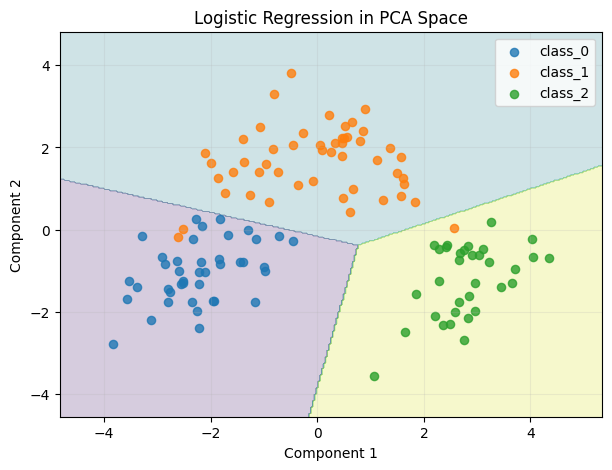

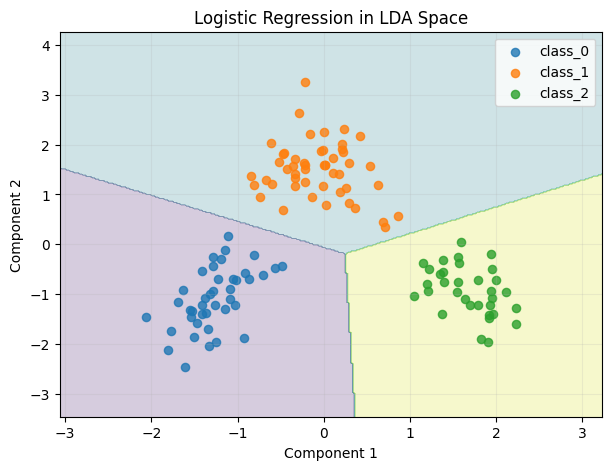

In [ ]:
def plot_decision_regions(Z, y, classifier, class_names, title):
    x_min, x_max = Z[:, 0].min() - 1.0, Z[:, 0].max() + 1.0
    y_min, y_max = Z[:, 1].min() - 1.0, Z[:, 1].max() + 1.0
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    grid_prediction = classifier.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, grid_prediction, alpha=0.22, cmap="viridis")
    for class_id, class_name in enumerate(class_names):
        mask = y == class_id
        plt.scatter(Z[mask, 0], Z[mask, 1], label=class_name, s=35, alpha=0.8)
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


plot_decision_regions(
    X_train_pca,
    y_train,
    trained_classifiers["PCA: 2 components"],
    wine.target_names,
    "Logistic Regression in PCA Space",
)

plot_decision_regions(
    X_train_lda,
    y_train,
    trained_classifiers["LDA: 2 components"],
    wine.target_names,
    "Logistic Regression in LDA Space",
)

## 22. Combined visualization and interpretation

PCA often gives a compact view of overall variation. LDA generally produces stronger class separation when labels are reliable. The result does not mean LDA is universally better:

- PCA can be applied without labels;
- PCA is suitable for compression and reconstruction;
- LDA may overfit when sample counts are small relative to dimensionality;
- LDA can be sensitive to outliers and violations of class assumptions; and
- supervised projections must be fitted inside each training fold during cross-validation.

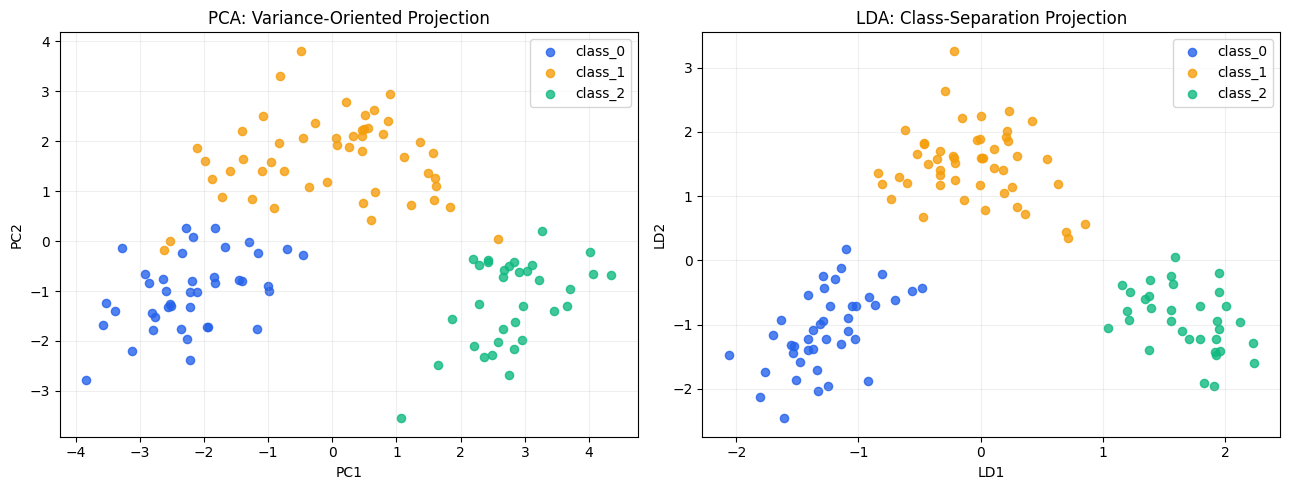

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#2563eb", "#f59e0b", "#10b981"]

for class_id, class_name in enumerate(wine.target_names):
    mask = y_train == class_id
    axes[0].scatter(
        X_train_pca[mask, 0], X_train_pca[mask, 1],
        label=class_name, color=colors[class_id], alpha=0.8, s=35,
    )
    axes[1].scatter(
        X_train_lda[mask, 0], X_train_lda[mask, 1],
        label=class_name, color=colors[class_id], alpha=0.8, s=35,
    )

axes[0].set_title("PCA: Variance-Oriented Projection")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].grid(alpha=0.2)
axes[0].legend()

axes[1].set_title("LDA: Class-Separation Projection")
axes[1].set_xlabel("LD1")
axes[1].set_ylabel("LD2")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

## 23. Common mistakes and debugging checklist

| Mistake | Consequence | Correction |
|---|---|---|
| Not scaling features | Large-scale variables dominate | Standardize using training statistics |
| Fitting PCA/LDA before splitting | Data leakage | Fit only on training data |
| Sorting eigenvalues ascending | Weak components selected first | Sort in descending order |
| Using `eig` without handling numerical complex parts | Unexpected complex values | Use `eigh` for symmetric covariance matrices |
| Forgetting label information in LDA | LDA cannot be constructed correctly | Calculate class-specific means and scatter |
| Requesting more than $C-1$ LDA components | Invalid dimensionality | Use at most $\min(d,C-1)$ |
| Directly comparing component signs | False mismatch | Compare explained variance or downstream results |
| Using the test set to choose components | Optimistically biased result | Choose using training/validation data |
| Inverting a singular $S_W$ directly | Numerical failure | Use regularization and pseudoinverse |

# Assignment: PCA and LDA on Handwritten Digits

**Dataset:** `sklearn.datasets.load_digits()`  
**Task:** Dimensionality reduction and multiclass classification  
**Total marks:** 20

The Digits dataset contains 1,797 images, 64 input features, and 10 classes. PCA can return up to 64 components, while LDA can return at most $10-1=9$ components.

## Assignment rules

1. Use a stratified 70/15/15 split with random state 42.
2. Fit the scaler, PCA, LDA, and classifier only on training data.
3. Implement the core PCA and LDA calculations using NumPy.
4. Use validation data to select dimensionality or other experimental choices.
5. Use the test set only once for the final selected configurations.
6. Keep all tables, figures, and outputs visible in the submitted notebook.

## Task 1 — Load the Digits dataset, print its shapes and class counts, and display one image from each class. **[1 mark]**

In [ ]:
# Task 1 solution
# Write your code here.

## Task 2 — Create a stratified 70/15/15 split and standardize features using statistics learned only from training data. **[2 marks]**

In [ ]:
# Task 2 solution
# Write your code here.

## Task 3 — Implement PCA from scratch using covariance and eigendecomposition, then verify eigenvalue ordering and component shapes. **[3 marks]**

In [ ]:
# Task 3 solution
# Write your code here.

## Task 4 — Plot explained and cumulative variance, and determine the smallest PCA dimension retaining at least 95% variance. **[2 marks]**

In [ ]:
# Task 4 solution
# Write your code here.

## Task 5 — Implement LDA from scratch using $S_W$ and $S_B$, include numerical regularization, and reduce the data to at most nine components. **[4 marks]**

In [ ]:
# Task 5 solution
# Write your code here.

## Task 6 — Compare scratch and Scikit-learn PCA/LDA using component counts, projection shapes, and validation classification accuracy. **[2 marks]**

In [ ]:
# Task 6 solution
# Write your code here.

## Task 7 — Plot the first two PCA and LDA components with digit classes shown in different colours. **[1 mark]**

In [ ]:
# Task 7 solution
# Write your code here.

## Task 8 — Compare Logistic Regression on full features, 95%-variance PCA features, and nine LDA features using validation data. **[2 marks]**

In [ ]:
# Task 8 solution
# Write your code here.

## Task 9 — Evaluate the selected configurations once on the test set using accuracy, macro precision, recall, F1-score, training time, and confusion matrices. **[2 marks]**

In [ ]:
# Task 9 solution
# Write your code here.

## Task 10 — Write a five-point comparison explaining when PCA or LDA should be preferred, supported by your measured results. **[1 mark]**

In [ ]:
# Task 10 solution
# Write your answer here as comments or add a Markdown cell.

## Assignment marks distribution

| Task | Component | Marks |
|---:|---|---:|
| 1 | Dataset inspection and visualization | 1 |
| 2 | Leakage-free split and standardization | 2 |
| 3 | PCA from scratch | 3 |
| 4 | Variance analysis and component selection | 2 |
| 5 | LDA from scratch | 4 |
| 6 | Scikit-learn verification | 2 |
| 7 | PCA/LDA visualization | 1 |
| 8 | Validation classification comparison | 2 |
| 9 | Final test evaluation | 2 |
| 10 | Interpretation | 1 |
|  | **Total** | **20** |